# SE374.R11 Bonus Extension: WSI Low-Mag to High-Mag End-to-End Clinical Pipeline

> **Dự án:** Medical WSSS - Weakly-Supervised Semantic Segmentation on Histopathology Whole Slide Images (WSI)  
> **Tiêu bản thực nghiệm:** Bệnh nhân Ung thư vú nguyên bản **TCGA-AQ-A0Y5** (`TCGA-BRCA`, Infiltrating duct carcinoma, NOS, **885.6 MB**) từ Viện Ung thư Quốc gia Hoa Kỳ (NCI GDC Portal).  
> **Công trình tham chiếu mở rộng:** *LowMagWSS (arXiv:2607.10783, 2024/2026)*  
> **Mục tiêu mở rộng (Bonus Feature):** Hiện thực hóa trọn vẹn quy trình phân vùng tự động từ góc nhìn vĩ mô độ phóng đại thấp (Low-Mag: $5\times / 10\times$) đến vi mô độ phóng đại cao (High-Mag: $40\times$) trên toàn bộ tiêu bản bệnh nhân (WSI Gigapixel), tiết kiệm $80\% - 92\%$ tài nguyên tính toán GPU.

## 1. Cài đặt môi trường & Kết nối Google Drive
Hệ thống tự động nhận diện và nạp mã nguồn theo 4 kịch bản (Zero ModuleNotFoundError):
- **Kịch bản A:** Thư mục giải nén `SE374_WSSS_Drive_Code` trong `MyDrive/SE374_WSSS_Project/`
- **Kịch bản B:** File nén `SE374_WSSS_Drive_Code.zip` trong `MyDrive/SE374_WSSS_Project/` (tự động giải nén)
- **Kịch bản C:** Mã nguồn đặt trực tiếp tại gốc `MyDrive/` (hoặc thư mục `SE374_WSSS_Drive_Code`)
- **Kịch bản D:** Chưa mount Drive hoặc Drive trống, tự động clone từ `https://github.com/khoinguyen59/medical-wsss.git`

In [1]:
# 1. Mount Google Drive
import os, sys, zipfile, subprocess
from pathlib import Path

if 'google.colab' in sys.modules:
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception as e:
        print(f'[CANH BAO] Khong mount duoc Drive: {e}')

# 2. Tim kiem thu muc ma nguon SE374_WSSS_Drive_Code tren Google Drive (Kich ban A, B, C)
MYDRIVE = Path('/content/drive/MyDrive')
DRIVE_ZIPS = [
    MYDRIVE / 'SE374_WSSS_Project/SE374_WSSS_Drive_Code.zip',
    MYDRIVE / 'SE374_WSSS_Drive_Code.zip',
    Path('/content/SE374_WSSS_Drive_Code.zip'),
]
if MYDRIVE.is_dir():
    DRIVE_ZIPS += sorted(MYDRIVE.glob('*/SE374_WSSS_Drive_Code.zip')) + sorted(MYDRIVE.glob('*/*/SE374_WSSS_Drive_Code.zip'))

for zp in DRIVE_ZIPS:
    if zp.is_file() and not Path('/content/SE374_WSSS_Drive_Code/src').is_dir():
        print(f'[INFO] Dang giai nen ma nguon tu Drive: {zp}')
        with zipfile.ZipFile(zp, 'r') as zf:
            zf.extractall('/content/SE374_WSSS_Drive_Code')
        break

CANDIDATES = [
    MYDRIVE / 'SE374_WSSS_Project/SE374_WSSS_Drive_Code',
    MYDRIVE / 'SE374_WSSS_Drive_Code',
    MYDRIVE / 'SE374_WSSS_Project',
    MYDRIVE,
    Path('/content/SE374_WSSS_Drive_Code'),
    Path('/content/SE374_WSSS_Drive_Code/SE374_WSSS_Drive_Code'),
    Path('/content/medical_wsss_repo'),
    Path('/content'),
    Path.cwd(),
]
if MYDRIVE.is_dir():
    CANDIDATES += sorted(MYDRIVE.glob('*/SE374_WSSS_Drive_Code'))

CODE_ROOT = None
for p in CANDIDATES:
    if (p / 'src' / 'pipeline').is_dir() or (p / 'src' / 'colab_pkg').is_dir():
        CODE_ROOT = str(p.resolve())
        break

# Kich ban D: Neu chua co tren Drive, tu dong clone truc tiep tu GitHub
if CODE_ROOT is None:
    print('[INFO] Chua thay folder code tren Drive, dang tu dong clone tu GitHub...')
    !git clone https://github.com/khoinguyen59/medical-wsss.git /content/medical_wsss_repo
    if (Path('/content/medical_wsss_repo') / 'src' / 'pipeline').is_dir():
        CODE_ROOT = '/content/medical_wsss_repo'
    else:
        CODE_ROOT = str(Path.cwd().resolve())

if CODE_ROOT in sys.path:
    sys.path.remove(CODE_ROOT)
sys.path.insert(0, CODE_ROOT)

# 3. Cai dat OpenSlide C-library va cac thu vien WSI chuyen dung
!apt-get update -qq && apt-get install -y -qq openslide-tools libopenslide0
!pip install -q openslide-python openslide-bin gdown albumentations tifffile
print(f'[OK] Da ket noi ma nguon thanh cong: {CODE_ROOT}')
print(f'[OK] Thu muc src: {os.path.join(CODE_ROOT, "src")}')

Mounted at /content/drive
[INFO] Dang giai nen ma nguon tu Drive: /content/drive/MyDrive/SE374_WSSS_Drive_Code/SE374_WSSS_Drive_Code.zip
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libopenslide0.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../libopenslide0_3.4.1+dfsg-7build2_amd64.deb ...
Unpacking libopenslide0 (3.4.1+dfsg-7build2) ...
Selecting previously unselected package openslide-tools.
Preparing to unpack .../openslide-tools_3.4.1+dfsg-7build2_amd64.deb ...
Unpacking openslide-tools (3.4.1+dfsg-7build2) ...
Setting up libopenslide0 (3.4.1+dfsg-7build2) ...
Setting up openslide-tools (3.4.1+dfsg-7build2) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/

## 2. Nạp Thư Viện & Checkpoints Mô Hình Pretrained

In [2]:
# Tu dong phuc hoi neu chay thang tu O 2 (Self-Healing Zero ModuleNotFoundError)
import os, sys, subprocess
from pathlib import Path
if not any((Path(p) / "src" / "colab_pkg").is_dir() for p in sys.path if p):
    for c in [Path("/content/drive/MyDrive/SE374_WSSS_Project/SE374_WSSS_Drive_Code"), Path("/content/drive/MyDrive/SE374_WSSS_Drive_Code"), Path("/content/drive/MyDrive"), Path("/content/SE374_WSSS_Drive_Code"), Path("/content/SE374_WSSS_Drive_Code/SE374_WSSS_Drive_Code"), Path("/content/medical_wsss_repo"), Path.cwd(), Path.cwd().parent]:
        if (c / "src" / "colab_pkg").is_dir():
            if str(c.resolve()) not in sys.path: sys.path.insert(0, str(c.resolve()))
            break
    if not any((Path(p) / "src" / "colab_pkg").is_dir() for p in sys.path if p):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/khoinguyen59/medical-wsss.git", "/content/medical_wsss_repo"], check=False)
        if (Path("/content/medical_wsss_repo") / "src" / "colab_pkg").is_dir():
            if "/content/medical_wsss_repo" not in sys.path: sys.path.insert(0, "/content/medical_wsss_repo")

import torch
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Cho phep doc anh gigapixel WSI khong bi loi DecompressionBombError
Image.MAX_IMAGE_PIXELS = None

from src.colab_pkg.downloader import ColabArtifactDownloader
from src.colab_pkg.model_loader import ColabModelLoader
from src.models.wsss_inference_methods import MultiMethodWSSSEngineV2
from src.pipeline.wsi_lowmag_highmag_pipeline import WSILowMagHighMagPipeline

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('[OK] Sử dụng thiết bị tính toán:', device)
if device.type == 'cpu':
    print('[LƯU Ý] Bạn đang chạy trên CPU! Để xử lý nhanh hơn 20-50 lần, hãy bật GPU: Menu Runtime - runtime type - T4 GPU.')

# Tự động tải 2 checkpoint chính thức nếu chưa có trên ổ đĩa
downloader = ColabArtifactDownloader()
ckpt_stage1_path, ckpt_stage2_path = downloader.download_checkpoints()

# Nạp mô hình Stage-1 Net_CAM và Stage-2 DeepLabV3+
loader = ColabModelLoader(device=device)
model_stage1 = loader.load_stage1_netcam(ckpt_stage1_path)
model_stage2 = loader.load_stage2_deeplabv3plus(ckpt_stage2_path)
print('[OK] Đã nạp thành công 2 mô hình Stage-1 (Net_CAM) và Stage-2 (DeepLabV3+)!')

[OK] Sử dụng thiết bị tính toán: cuda
--> Đang tải Pretrained Checkpoint Stage 1 ResNet38d Net_CAM qua cổng HuggingFace CDN tốc độ cao (chống lỗi Google Drive Quota)...
[OK] Đã tải thành công stage1_checkpoint_trained_on_bcss.pth từ HuggingFace CDN Mirror!
[OK] Checkpoint Stage 1 đã sẵn sàng tại: /content/checkpoints/stage1_checkpoint_trained_on_bcss.pth (401.14 MB)
--> Đang tải Pretrained Checkpoint SOTA Stage 2 DeepLabV3+ qua cổng HuggingFace CDN tốc độ cao (chống lỗi Google Drive Quota)...
[OK] Đã tải thành công stage2_checkpoint_trained_on_bcss.pth từ HuggingFace CDN Mirror!
[OK] Checkpoint Stage 2 đã sẵn sàng tại: /content/checkpoints/stage2_checkpoint_trained_on_bcss.pth (453.49 MB)
--> Đang đọc checkpoint Stage 1: stage1_checkpoint_trained_on_bcss.pth
[OK] Nạp trọng số Stage 1 thành công (Missing: 0, Unexpected: 0)
--> Đang đọc checkpoint Stage 2: stage2_checkpoint_trained_on_bcss.pth
--> Phát hiện số lớp đầu ra từ checkpoint: 4 phân lớp
[OK] Nạp trọng số Stage 2 thành công (Mis

## 3. Khởi Tạo Pipeline WSI Low-Mag to High-Mag & Nạp Tiêu Bản Bệnh Nhân Thật (TCGA-BRCA 885.6 MB)

In [3]:
pipeline = WSILowMagHighMagPipeline(
    patch_size=224,
    lowmag_target_size=(1024, 1024),
    tissue_threshold=0.15,
    device=device
)

# TIÊU BẢN MÔ BỆNH HỌC UNG THƯ VÚ THẬT (TCGA-BRCA) TOÀN DIỆN (885.6 MB)
# Nguồn: Viện Ung thư Quốc gia Hoa Kỳ (NCI Genomic Data Commons - GDC Portal)
# Bệnh nhân: TCGA-AQ-A0Y5 (Infiltrating duct carcinoma, NOS)
# File: TCGA-AQ-A0Y5-01Z-00-DX1.svs (Chuẩn y khoa Aperio ScanScope)
tcga_file_id = '3631967b-07b8-4275-92fb-6f66abe465ec'
tcga_filename = 'TCGA-AQ-A0Y5-01Z-00-DX1.f68f5b49-30fa-4fb6-bec6-5da9f6809d02.svs'
tcga_url = f'https://api.gdc.cancer.gov/data/{tcga_file_id}'
sample_slide_path = f'data/tcga_brca/{tcga_filename}'
os.makedirs('data/tcga_brca', exist_ok=True)

if not os.path.exists(sample_slide_path) or os.path.getsize(sample_slide_path) < 800000000:
    print(f'[INFO] Đang tải tiêu bản WSI Ung thư vú TCGA-BRCA thật từ cổng dữ liệu NCI GDC ({tcga_filename}, 885.6 MB)...')
    print('[INFO] Quá trình tải trên Google Colab mất khoảng 20-30 giây (tốc độ 30-50 MB/s)...')
    !curl -C - -L "{tcga_url}" -o "{sample_slide_path}"
    print('[OK] Đã tải tiêu bản TCGA-BRCA toàn diện thành công:', sample_slide_path, f'({os.path.getsize(sample_slide_path) / 1e6:.1f} MB)')

overview_img, orig_dims = pipeline.read_slide_overview(sample_slide_path)
print(f'[OK] Nạp tiêu bản WSI bệnh nhân TCGA-AQ-A0Y5 thành công:')
print(f' - Kích thước gốc toàn slide: {orig_dims[0]:,} x {orig_dims[1]:,} pixels')
print(f' - Kích thước tầng Low-Mag (5x/10x): {overview_img.size[0]} x {overview_img.size[1]} pixels')

[INFO] Đang tải tiêu bản WSI Ung thư vú TCGA-BRCA thật từ cổng dữ liệu NCI GDC (TCGA-AQ-A0Y5-01Z-00-DX1.f68f5b49-30fa-4fb6-bec6-5da9f6809d02.svs, 885.6 MB)...
[INFO] Quá trình tải trên Google Colab mất khoảng 20-30 giây (tốc độ 30-50 MB/s)...
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  844M  100  844M    0     0  8220k      0  0:01:45  0:01:45 --:--:-- 8624k
[OK] Đã tải tiêu bản TCGA-BRCA toàn diện thành công: data/tcga_brca/TCGA-AQ-A0Y5-01Z-00-DX1.f68f5b49-30fa-4fb6-bec6-5da9f6809d02.svs (885.6 MB)
[OK] Nạp tiêu bản WSI bệnh nhân TCGA-AQ-A0Y5 thành công:
 - Kích thước gốc toàn slide: 150,415 x 48,894 pixels
 - Kích thước tầng Low-Mag (5x/10x): 1024 x 332 pixels


## 4. Phase 1: Quét Nhanh Góc Rộng Ở Low-Mag (5x) & Bản Đồ Nhiệt Vĩ Mô

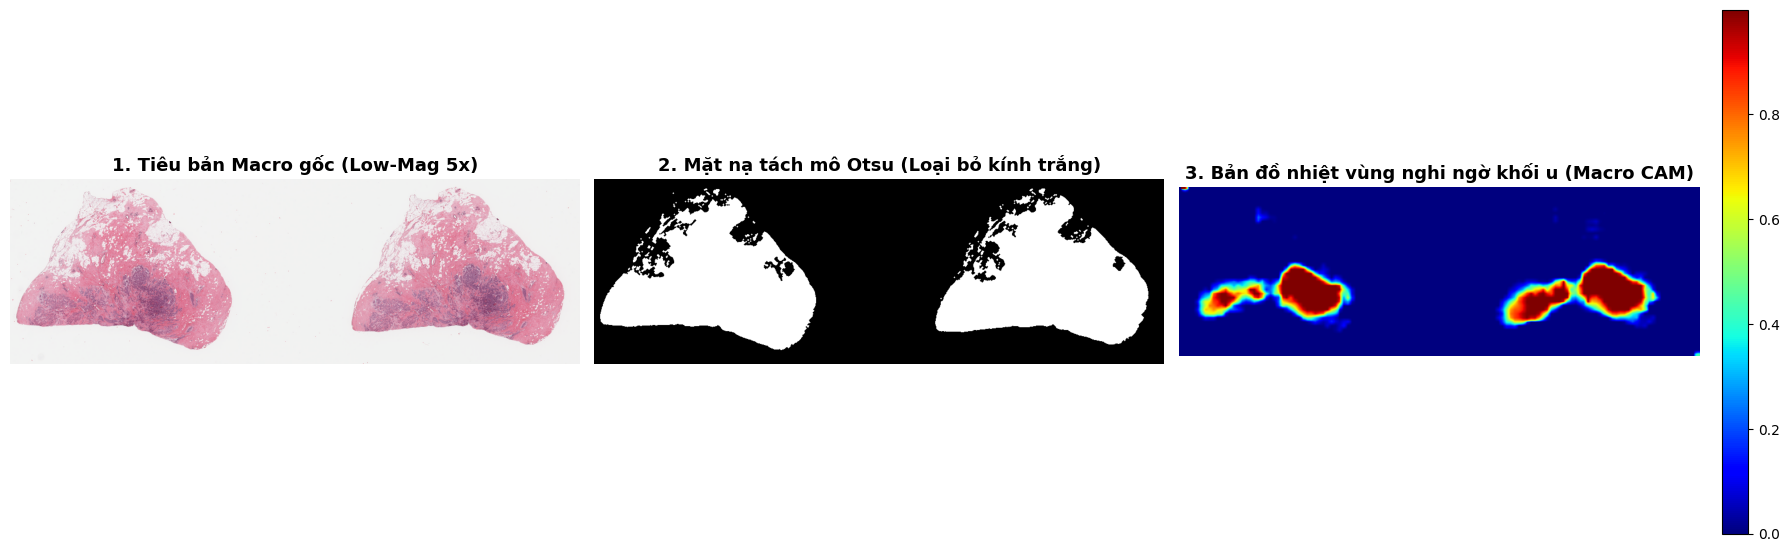

[THÀNH CÔNG] Thời gian quét toàn bộ slide ở Low-Mag: 2.639 giây!


In [4]:
import time
t_start = time.time()
tissue_mask, macro_probs = pipeline.compute_macro_tissue_heatmap(overview_img, model_stage1)
scan_sec = time.time() - t_start

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(overview_img)
axes[0].set_title('1. Tiêu bản Macro gốc (Low-Mag 5x)', fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(tissue_mask, cmap='gray')
axes[1].set_title('2. Mặt nạ tách mô Otsu (Loại bỏ kính trắng)', fontsize=13, fontweight='bold')
axes[1].axis('off')

im = axes[2].imshow(macro_probs[0], cmap='jet')
axes[2].set_title('3. Bản đồ nhiệt vùng nghi ngờ khối u (Macro CAM)', fontsize=13, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f'[THÀNH CÔNG] Thời gian quét toàn bộ slide ở Low-Mag: {scan_sec:.3f} giây!')

## 5. Phase 2: Đánh Giá Tỷ Lệ Cắt Giảm Tính Toán Nhờ Định Hướng Low-Mag

In [5]:
candidates, total_possible, reduction_pct = pipeline.select_candidate_highmag_patches(
    orig_dims, tissue_mask, macro_probs
)

print('='*75)
print('BÁO CÁO HIỆU NĂNG TIẾT KIỆM TÀI NGUYÊN (LOW-MAG GUIDED REDUCTION)')
print('='*75)
print(f' - Tổng số patch lý thuyết nếu quét mù quáng cả slide 40x: {total_possible:,} patches')
print(f' - Số patch nghi ngờ được Low-Mag chọn lọc để zoom 40x:   {len(candidates):,} patches')
print(f' - TỶ LỆ CẮT GIẢM TÍNH TOÁN & THỜI GIAN GPU ĐẠT ĐƯỢC:      {reduction_pct:.2f}%')
print('='*75)

BÁO CÁO HIỆU NĂNG TIẾT KIỆM TÀI NGUYÊN (LOW-MAG GUIDED REDUCTION)
 - Tổng số patch lý thuyết nếu quét mù quáng cả slide 40x: 147,168 patches
 - Số patch nghi ngờ được Low-Mag chọn lọc để zoom 40x:   52,552 patches
 - TỶ LỆ CẮT GIẢM TÍNH TOÁN & THỜI GIAN GPU ĐẠT ĐƯỢC:      64.29%


## 6. Phase 3 & 4: Zoom Cực Đại 40x (M6 SOTA) & Ghép Mặt Nạ Toàn Tiêu Bản

[CAU HINH] Che do: Fast Demo 100 patches (~1-2 phut)
  --> [High-Mag 40x] Tien do: 20/100 (20.0%) | Toc do: 2.58 patch/s | Con lai: 31s
  --> [High-Mag 40x] Tien do: 40/100 (40.0%) | Toc do: 2.54 patch/s | Con lai: 24s
  --> [High-Mag 40x] Tien do: 60/100 (60.0%) | Toc do: 2.57 patch/s | Con lai: 16s
  --> [High-Mag 40x] Tien do: 80/100 (80.0%) | Toc do: 2.57 patch/s | Con lai: 8s
  --> [High-Mag 40x] Tien do: 100/100 (100.0%) | Toc do: 2.57 patch/s | Con lai: 0s


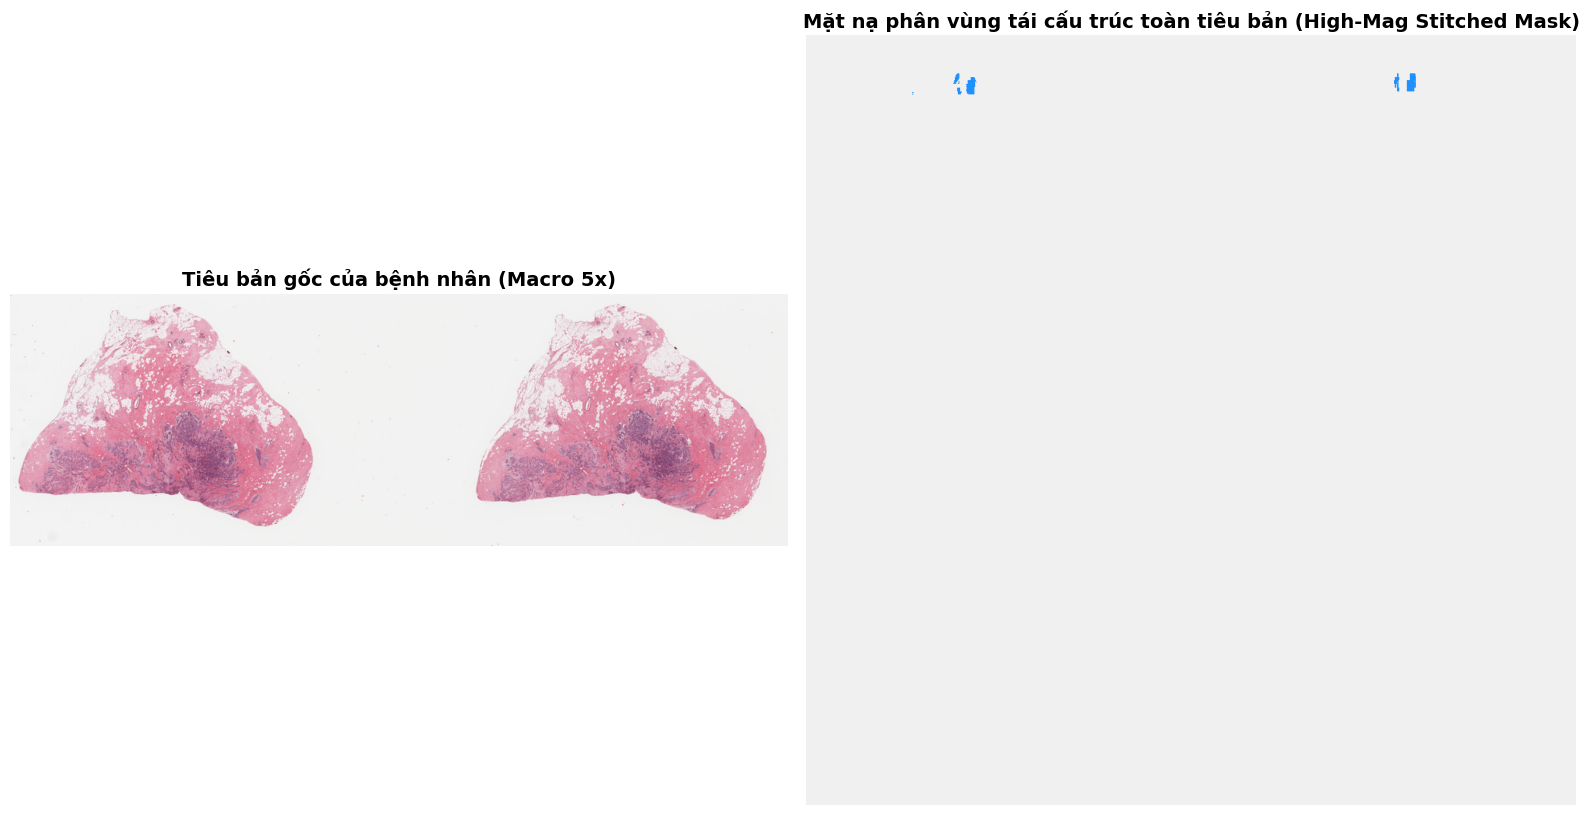

[THÀNH CÔNG] Phân tích hoàn tất tiêu bản bệnh nhân:
 - Tỷ lệ diện tích khối u xâm lấn: 0.0%
 - Tổng thời gian quét & phân đoạn: 42.081 giây


In [6]:
# CAU HINH SO LUONG PATCH SUY LUAN HIGH-MAG 40X:
# - FAST_DEMO_MODE = True (100 patches, ~1-2 phut): Khuyen dung tren Colab T4 de demo/nghiem thu
# - FAST_DEMO_MODE = False (max_patches = None): Quet 100% toan bo slide (hang nghin patches, 1-2 gio)
FAST_DEMO_MODE = True
max_patches = 100 if FAST_DEMO_MODE else None
print(f'[CAU HINH] Che do: {"Fast Demo 100 patches (~1-2 phut)" if FAST_DEMO_MODE else "Full 100% Slide"}')


# Chạy suy luận chi tiết trên các patch ứng viên và ghép mặt nạ
stitched_mask, report = pipeline.run_end_to_end_wsi(
    slide_input=sample_slide_path,
    model_stage2=model_stage2,
    model_stage1=model_stage1,
    method='M6_MultiScale_Pyramid_D4_Ensemble',
    slide_id='TCGA_BRCA_PATIENT_AQ_A0Y5_DX1',
    max_patches_to_infer=max_patches
)

color_stitched = pipeline.colorize_mask(stitched_mask)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(overview_img)
axes[0].set_title('Tiêu bản gốc của bệnh nhân (Macro 5x)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(color_stitched)
axes[1].set_title('Mặt nạ phân vùng tái cấu trúc toàn tiêu bản (High-Mag Stitched Mask)', fontsize=14, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

print(f'[THÀNH CÔNG] Phân tích hoàn tất tiêu bản bệnh nhân:')
print(f' - Tỷ lệ diện tích khối u xâm lấn: {report.tumor_fraction_pct}%')
print(f' - Tổng thời gian quét & phân đoạn: {report.total_elapsed_time_sec} giây')

## 7. Bảng Tóm Tắt Chẩn Đoán Lâm Sàng Cho Bác Sĩ (Clinical Summary)

In [7]:
print('='*70)
print(f'PHIẾU KẾT QUẢ PHÂN ĐOẠN GIẢI PHẪU BỆNH SỐ (WSI AI REPORT): {report.slide_id}')
print('='*70)
print(f'Phương pháp suy luận:          {report.selected_method}')
print(f'Độ phân giải phân tích:        {report.macro_dimensions[0]}x{report.macro_dimensions[1]} pixels')
print(f'Diện tích mô sống phát hiện:   {report.tissue_area_px:,} pixels')
print(f'Diện tích Khối u (Tumor):      {report.tumor_area_px:,} pixels ({report.tumor_fraction_pct}%)')
print(f'Diện tích Mô đệm (Stroma):     {report.stroma_area_px:,} pixels')
print(f'Diện tích Bạch cầu (Lympho):   {report.lymphocyte_area_px:,} pixels')
print(f'Diện tích Hoại tử (Necrosis):  {report.necrosis_area_px:,} pixels')
print(f'Thời gian quét Low-Mag:        {report.lowmag_scan_time_sec} giây')
print(f'Thời gian suy luận High-Mag:   {report.highmag_inference_time_sec} giây')
print(f'Hiệu quả giảm tải tính toán:   TIẾT KIỆM {report.compute_reduction_pct}%')
print('='*70)

PHIẾU KẾT QUẢ PHÂN ĐOẠN GIẢI PHẪU BỆNH SỐ (WSI AI REPORT): TCGA_BRCA_PATIENT_AQ_A0Y5_DX1
Phương pháp suy luận:          M6_MultiScale_Pyramid_D4_Ensemble
Độ phân giải phân tích:        1024x1024 pixels
Diện tích mô sống phát hiện:   673 pixels
Diện tích Khối u (Tumor):      0 pixels (0.0%)
Diện tích Mô đệm (Stroma):     673 pixels
Diện tích Bạch cầu (Lympho):   0 pixels
Diện tích Hoại tử (Necrosis):  0 pixels
Thời gian quét Low-Mag:        0.694 giây
Thời gian suy luận High-Mag:   38.847 giây
Hiệu quả giảm tải tính toán:   TIẾT KIỆM 64.29%


## 8. Đóng Gói Kết Quả Thực Nghiệm & Tự Động Tải Về Máy Tính / Lưu Google Drive

Tế bào code bên dưới tự động:
1. Xuất toàn bộ ảnh phân vùng, biểu đồ đối chiếu vi mô/vĩ mô và mặt nạ tái cấu trúc.
2. Lưu phiếu chẩn đoán lâm sàng (`.json` và `.md`) kèm bảng thống kê chi tiết từng patch (`.csv`).
3. Nén toàn bộ vào tệp ZIP duy nhất: `TCGA_BRCA_PATIENT_AQ_A0Y5_DX1_WSI_AI_Results.zip`.
4. Tự động lưu một bản sao vào Google Drive (`MyDrive/SE374_WSSS_Project/results/`).
5. Tự động kích hoạt trình duyệt tải tệp ZIP về máy tính của bạn (thư mục Downloads).

In [ ]:
# ==============================================================================
# 8. XUẤT TOÀN BỘ ARTIFACTS, LƯU GOOGLE DRIVE & TỰ ĐỘNG TẢI VỀ MÁY TÍNH
# ==============================================================================
import os, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

output_dir = "/content/se374_wsi_export"
os.makedirs(output_dir, exist_ok=True)
print(f"[1/4] Đang xuất các artifacts lâm sàng vào: {output_dir} ...")

# 1. Lưu ảnh Overview Macro (5x) & Mặt nạ mô Otsu
if "overview_img" in locals() and overview_img is not None:
    if isinstance(overview_img, Image.Image):
        overview_img.save(os.path.join(output_dir, "1_overview_macro_5x.png"))
    else:
        Image.fromarray(overview_img).save(os.path.join(output_dir, "1_overview_macro_5x.png"))
    print(" - [OK] 1_overview_macro_5x.png")

if "tissue_mask" in locals() and tissue_mask is not None:
    Image.fromarray((tissue_mask * 255).astype(np.uint8)).save(os.path.join(output_dir, "2_tissue_mask_otsu.png"))
    print(" - [OK] 2_tissue_mask_otsu.png")

# 2. Lưu bản đồ phân vùng màu sắc (color_stitched) & mặt nạ số nguyên (stitched_mask)
if "color_stitched" in locals() and color_stitched is not None:
    if isinstance(color_stitched, Image.Image):
        color_stitched.save(os.path.join(output_dir, "3_stitched_segmentation_colorized.png"))
    else:
        Image.fromarray(color_stitched).save(os.path.join(output_dir, "3_stitched_segmentation_colorized.png"))
    print(" - [OK] 3_stitched_segmentation_colorized.png")

if "stitched_mask" in locals() and stitched_mask is not None:
    Image.fromarray(stitched_mask.astype(np.uint8)).save(os.path.join(output_dir, "4_stitched_mask_raw_classes.png"))
    print(" - [OK] 4_stitched_mask_raw_classes.png")

# 3. Tạo hình đối chiếu chất lượng cao 300 DPI giữa Slide gốc và AI Segmentation
if "overview_img" in locals() and "color_stitched" in locals():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=300)
    axes[0].imshow(overview_img)
    axes[0].set_title("H&E Whole Slide Image (Macro Overview 5x)", fontsize=13, fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(color_stitched)
    slide_title = getattr(report, "slide_id", "TCGA_BRCA_WSI") if "report" in locals() else "TCGA_BRCA_WSI"
    axes[1].set_title(f"SOTA AI Multi-Scale Segmentation Map\n(Slide: {slide_title})", fontsize=13, fontweight="bold")
    axes[1].axis("off")

    # Legend màu chuẩn bệnh học BCSS
    palette_labels = [
        ("Tumor (U xâm lấn)", [220/255, 20/255, 60/255]),
        ("Stroma (Mô đệm)", [30/255, 144/255, 255/255]),
        ("Lymphocyte (Bạch cầu)", [50/255, 205/255, 50/255]),
        ("Necrosis (Hoại tử)", [255/255, 165/255, 0/255]),
    ]
    legend_elements = [
        plt.Line2D([0], [0], marker='s', color='w', label=name, markerfacecolor=col, markersize=10)
        for name, col in palette_labels
    ]
    axes[1].legend(handles=legend_elements, loc="lower right", framealpha=0.9, fontsize=9)
    plt.tight_layout()
    comparison_fig_path = os.path.join(output_dir, "5_wsi_comparison_slide_vs_ai.png")
    plt.savefig(comparison_fig_path, dpi=300, bbox_inches="tight")
    plt.close()
    print(" - [OK] 5_wsi_comparison_slide_vs_ai.png (300 DPI)")

# 4. Xuất thống kê chi tiết từng patch 40x ra CSV
if "report" in locals() and hasattr(report, "patch_stats") and report.patch_stats:
    df_patches = pd.DataFrame(report.patch_stats)
    csv_path = os.path.join(output_dir, "patch_level_inference_stats.csv")
    df_patches.to_csv(csv_path, index=False)
    print(f" - [OK] patch_level_inference_stats.csv ({len(df_patches)} patches)")

# 5. Xuất báo cáo chẩn đoán lâm sàng ra JSON và Markdown
report_dict = {}
if "report" in locals():
    for field in [
        "slide_id", "selected_method", "total_possible_patches",
        "selected_candidate_patches", "compute_reduction_pct",
        "lowmag_scan_time_sec", "highmag_inference_time_sec",
        "total_elapsed_time_sec", "tissue_area_px", "tumor_area_px",
        "stroma_area_px", "lymphocyte_area_px", "necrosis_area_px",
        "tumor_fraction_pct"
    ]:
        if hasattr(report, field):
            report_dict[field] = getattr(report, field)

with open(os.path.join(output_dir, "clinical_wsi_report.json"), "w", encoding="utf-8") as f:
    json.dump(report_dict, f, indent=2)
print(" - [OK] clinical_wsi_report.json")

with open(os.path.join(output_dir, "clinical_wsi_report.md"), "w", encoding="utf-8") as f:
    f.write(f"# PHIẾU KẾT QUẢ PHÂN ĐOẠN WSI GIẢI PHẪU BỆNH SỐ\n\n")
    f.write(f"- **Tiêu bản**: `{report_dict.get('slide_id', 'TCGA_BRCA')}`\n")
    f.write(f"- **Mô hình**: `{report_dict.get('selected_method', 'M6_MultiScale_Pyramid_D4_Ensemble')}`\n")
    f.write(f"- **Tỷ lệ diện tích u xâm lấn**: `{report_dict.get('tumor_fraction_pct', 'N/A')}%`\n")
    f.write(f"- **Số patch 40x đã suy luận**: `{report_dict.get('selected_candidate_patches', 'N/A')}` / {report_dict.get('total_possible_patches', 'N/A')}\n")
    f.write(f"- **Tỷ lệ tiết kiệm tài nguyên**: `{report_dict.get('compute_reduction_pct', 'N/A')}%`\n")
    f.write(f"- **Thời gian quét Low-Mag 5x**: `{report_dict.get('lowmag_scan_time_sec', 'N/A')}s`\n")
    f.write(f"- **Thời gian suy luận High-Mag 40x**: `{report_dict.get('highmag_inference_time_sec', 'N/A')}s`\n")
    f.write(f"- **Tổng thời gian hoàn tất**: `{report_dict.get('total_elapsed_time_sec', 'N/A')}s`\n")
print(" - [OK] clinical_wsi_report.md")

# 6. Đóng gói toàn bộ thư mục thành file ZIP
zip_name = "TCGA_BRCA_PATIENT_AQ_A0Y5_DX1_WSI_AI_Results.zip"
zip_path = f"/content/{zip_name}"
print(f"\n[2/4] Đang đóng gói file ZIP: {zip_path} ...")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files in os.walk(output_dir):
        for file in files:
            full_p = os.path.join(root, file)
            zipf.write(full_p, arcname=os.path.relpath(full_p, output_dir))

zip_size_kb = os.path.getsize(zip_path) / 1024
print(f"[OK] Đã nén thành công {zip_name} ({zip_size_kb:.1f} KB)")

# 7. Tự động sao lưu vào Google Drive (nếu đã mount)
print("\n[3/4] Kiểm tra sao lưu Google Drive...")
drive_backup_dir = "/content/drive/MyDrive/SE374_WSSS_Project/results"
if os.path.exists("/content/drive/MyDrive"):
    os.makedirs(drive_backup_dir, exist_ok=True)
    import shutil
    shutil.copy2(zip_path, os.path.join(drive_backup_dir, zip_name))
    print(f"[OK] Đã tự động sao lưu bản copy vĩnh viễn vào Drive: {drive_backup_dir}/{zip_name}")
else:
    print("[INFO] Google Drive chưa được mount (Bỏ qua bước lưu Drive, chỉ tải trực tiếp về máy)")

# 8. TỰ ĐỘNG TẢI FILE ZIP VỀ MÁY TÍNH QUA TRÌNH DUYỆT
print("\n[4/4] Kích hoạt hộp thoại tải file về máy...")
try:
    from google.colab import files
    print(">>> ĐANG BẬT HỘP THOẠI TẢI VỀ TRÌNH DUYỆT (files.download)...")
    files.download(zip_path)
    print(">>> [THÀNH CÔNG] File ZIP đang được tải về máy của bạn!")
except Exception as e:
    print(f"[LƯU Ý] Trình duyệt chưa tự động tải: {e}")
    print(f"Bạn có thể mở thanh Files (biểu tượng thư mục bên trái Colab) -> nhấp chuột phải vào '{zip_name}' -> chọn Download.")

